# Bài tập thực hành 1
Xây dựng mô hình Naïve ngây thơ trên tập dữ liệu hành vi của khách hàng

## Khai báo thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

## Đọc dữ liệu

In [3]:
df = pd.read_csv("data/Customer_Behaviour.csv")

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

df = df.rename(columns={
    "estimatedsalary": "estimated_salary"
})

print(df.head())
print("Kích thước dữ liệu:", df.shape)
print("Tên các cột:", df.columns.tolist())
print(df.isna().sum())

    user_id  gender  age  estimated_salary  purchased
0  15624510    Male   19             19000          0
1  15810944    Male   35             20000          0
2  15668575  Female   26             43000          0
3  15603246  Female   27             57000          0
4  15804002    Male   19             76000          0
Kích thước dữ liệu: (400, 5)
Tên các cột: ['user_id', 'gender', 'age', 'estimated_salary', 'purchased']
user_id             0
gender              0
age                 0
estimated_salary    0
purchased           0
dtype: int64


## Xác định X và y

In [4]:
required_columns = {
    "gender", "age", "estimated_salary", "purchased"
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Thiếu các cột: {sorted(missing_columns)}"
    )

df["purchased"] = pd.to_numeric(
    df["purchased"], errors="coerce"
)

df = df.dropna(subset=["purchased"])

X = df[["gender", "age", "estimated_salary"]]
y = df["purchased"].astype(int)

print("Số lượng từng lớp:")
print(y.value_counts().sort_index())

Số lượng từng lớp:
purchased
0    257
1    143
Name: count, dtype: int64


## Chia dữ liệu

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Số mẫu train:", len(X_train))
print("Số mẫu test:", len(X_test))

Số mẫu train: 320
Số mẫu test: 80


## Tiền xử lý và tạo mô hình

In [6]:
numeric_features = ["age", "estimated_salary"]
categorical_features = ["gender"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    sparse_threshold=0
)

nb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB())
])

nb_model.fit(X_train, y_train)

print("Đã huấn luyện xong Naive Bayes.")

Đã huấn luyện xong Naive Bayes.


## Dự đoán và đánh giá

Accuracy: 0.8875
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.92      0.91        51
           1       0.86      0.83      0.84        29

    accuracy                           0.89        80
   macro avg       0.88      0.87      0.88        80
weighted avg       0.89      0.89      0.89        80



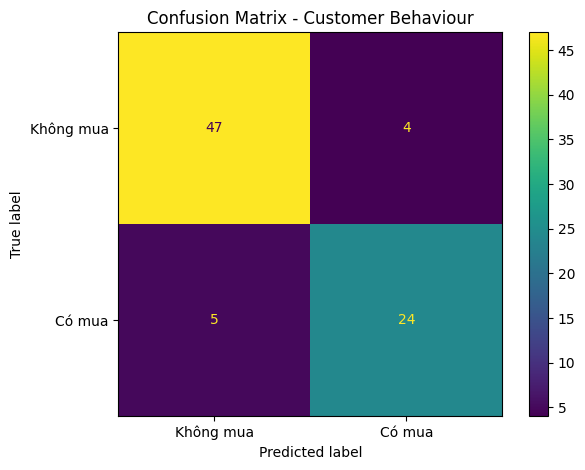

In [7]:
y_pred = nb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Classification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Không mua", "Có mua"]
)

plt.title("Confusion Matrix - Customer Behaviour")
plt.tight_layout()
plt.show()